In [1]:
import geopandas as gpd
from matplotlib import pyplot as plt
import pandas as pd
retail_centres = gpd.read_parquet("../data/output_files/mergeafterfiltthresh_retailcen_foursquare_mrc_2_mri_1_mrn_10_mtf_6_splitthresh_1500_merge_y/4_finalcentres.parquet")

In [2]:
print(len(retail_centres))

10887


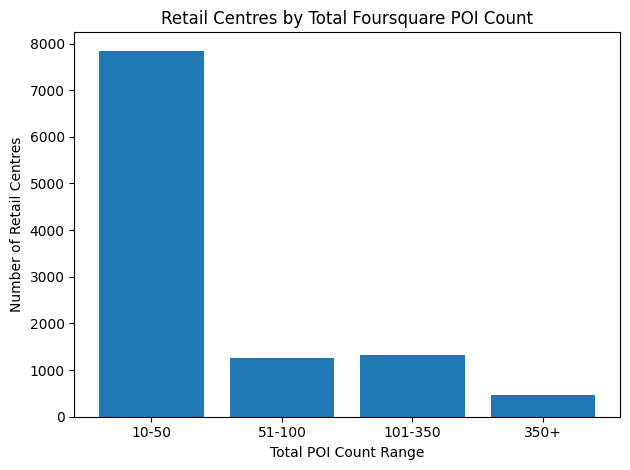

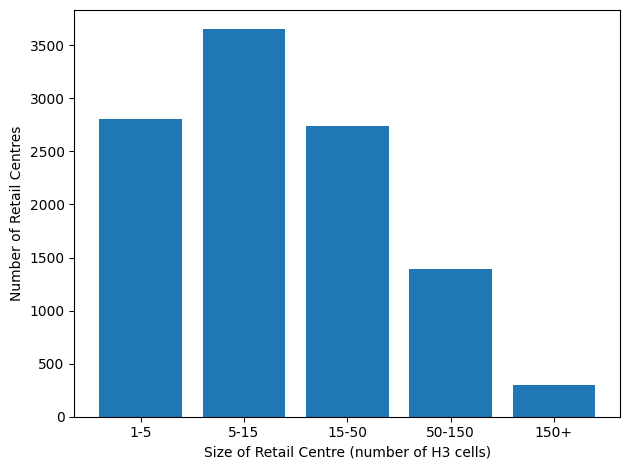

In [25]:
import numpy as np


# Example POI counts array
poi_counts = np.array(retail_centres['Total_POI_count'])

# Define custom bins
bins = [ 10, 50, 100, 350, np.inf]
labels = ["10-50", "51-100", "101-350", "350+"]

# Compute histogram in these bins
hist, _ = np.histogram(poi_counts, bins=bins)

# Plot bar chart
plt.bar(labels, hist)
plt.xlabel('Total POI Count Range')
plt.ylabel('Number of Retail Centres')
plt.title('Retail Centres by Total Foursquare POI Count')
plt.tight_layout()
plt.show()


#similar fo # H3 count

h3_counts = np.array(retail_centres['# H3 cells'])
bins = [1, 5, 15, 50, 150, np.inf]
labels = ["1-5", "5-15", "15-50", "50-150", "150+"]
# Compute histogram in these bins
hist, _ = np.histogram(h3_counts, bins=bins)
# Plot bar chart
plt.bar(labels, hist)
plt.xlabel('Size of Retail Centre (number of H3 cells)')
plt.ylabel('Number of Retail Centres')
plt.tight_layout()

In [26]:
#3_afterfill.parquet from same folder
cells = gpd.read_parquet("../data/output_files/mergeafterfiltthresh_retailcen_foursquare_mrc_2_mri_1_mrn_10_mtf_6_splitthresh_1500_merge_y/3_afterfill.parquet")

In [30]:
import geopandas as gpd

# Ensure both GeoDataFrames use the same CRS
gdf_h3 = cells.to_crs("EPSG:27700")  # example: British National Grid
gdf_rc =retail_centres.to_crs(gdf_h3.crs)    # match H3 CRS

# Perform spatial join: join H3s to RCs they fall within
joined = gpd.sjoin(gdf_h3, gdf_rc[['RC_ID', 'geometry']], how='left', predicate='within')

# Select just what you need
h3_to_rc = joined[['h3_11', 'RC_ID']]


In [32]:
h3_to_rc

#are there any cells that don't have a retail centre?
missing_rc = h3_to_rc[h3_to_rc['RC_ID'].isna()]
missing_rc_count = missing_rc['h3_11'].nunique()
print(f"Number of H3 cells without a retail centre: {missing_rc_count}")

Number of H3 cells without a retail centre: 0


In [34]:
#sort by RC_ID
h3_to_rc = h3_to_rc.sort_values(by='RC_ID')

In [35]:
#SAVE h3_to_rc to some formats inc csv and parquet
h3_to_rc.to_csv("../data/output_files/h3_to_rc.csv", index=False)
h3_to_rc.to_parquet("../data/output_files/h3_to_rc.parquet", index=False)
h3_to_rc.to_file("../data/output_files/h3_to_rc.geojson", driver='GeoJSON')

AttributeError: 'DataFrame' object has no attribute 'to_file'

There are 12044 retail centres.


array([[<Axes: title={'center': 'trackNodes'}>]], dtype=object)

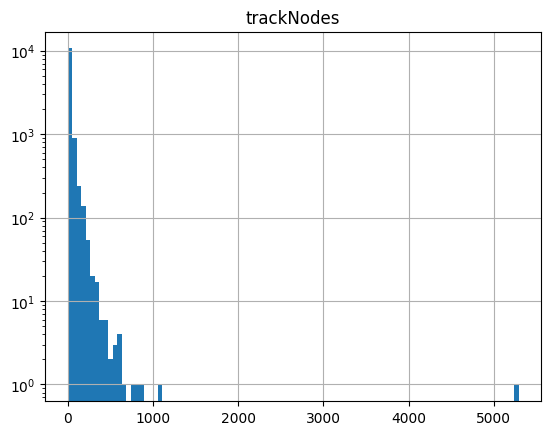

In [43]:
print("There are {} retail centres.".format(len(retail_centres)))

retail_centres.hist(column="trackNodes", bins=100, log=True)

In [44]:
#print the h3 of the top 10 retail centres
print("Top 10 retail centres by number of track nodes:")
top_10_centres = retail_centres.nlargest(500, "trackNodes")
#add the rank column
top_10_centres["rank"] = range(1, len(top_10_centres) + 1)
#change settings so all rows are printed
pd.set_option("display.max_rows", None)

print(top_10_centres[["rank","h3_11", "trackNodes"]])

Top 10 retail centres by number of track nodes:
       rank            h3_11  trackNodes
4018      1  8b195da49b82fff        5289
11385     2  8b1972765219fff        1064
470       3  8b1909ac5bb0fff         881
1564      4  8b1951b75c24fff         807
6225      5  8b1951b0baa0fff         781
1996      6  8b1942c5d694fff         667
12018     7  8b1976bb66e8fff         632
8755      8  8b195c05bb36fff         631
3120      9  8b194a721963fff         628
4817     10  8b194e652752fff         594
1089     11  8b19420c962efff         570
5519     12  8b19510732e4fff         549
11246    13  8b195dd605a0fff         543
4525     14  8b194e144351fff         522
4098     15  8b195da6bb41fff         491
4072     16  8b194ad34a12fff         472
2428     17  8b1943580762fff         465
4076     18  8b195da69975fff         460
521      19  8b1909ad5585fff         437
2405     20  8b19434db372fff         435
7143     21  8b19580c8562fff         428
5680     22  8b1951104a2efff         412
9388     

In [27]:
land_use_cells

,landuse,h3_11
21575,retail,8b194aaaeda3fff
21575,retail,8b194aaaed04fff
21575,retail,8b194aaaed30fff
21575,retail,8b194aaaeda0fff
21575,retail,8b194aaaedacfff
...,...,...
4955,retail,8b1928883bb2fff
4955,retail,8b19288838e9fff
4955,retail,8b1928883bb6fff
4955,retail,8b19288838ccfff


There are 6423 retail centres.


array([[<Axes: title={'center': 'H3_count'}>]], dtype=object)

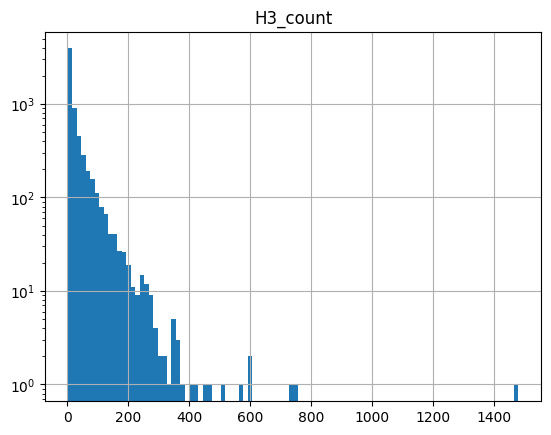

In [39]:
old_retail_centres = gpd.read_file("../data/old_retail_centres/Retail_Boundaries_UK.gpkg")

print("There are {} retail centres.".format(len(old_retail_centres)))

old_retail_centres.hist(column="H3_count", bins=100, log=True)

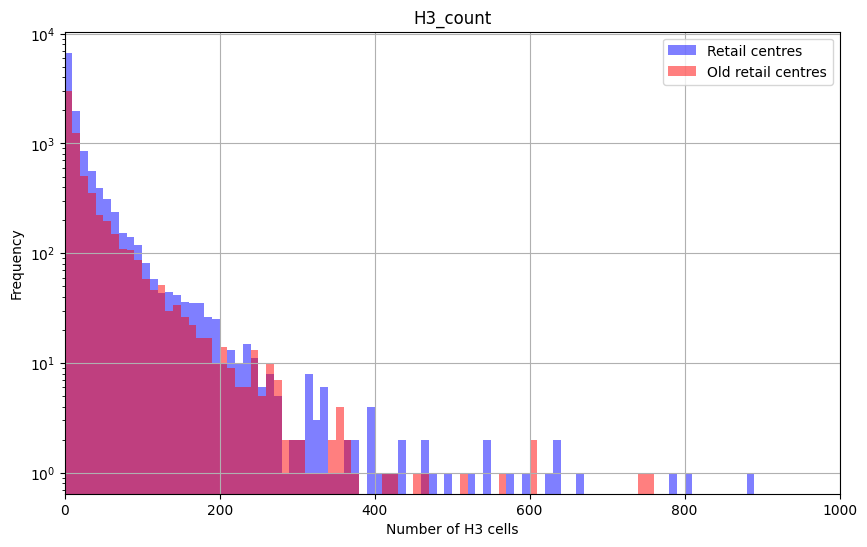

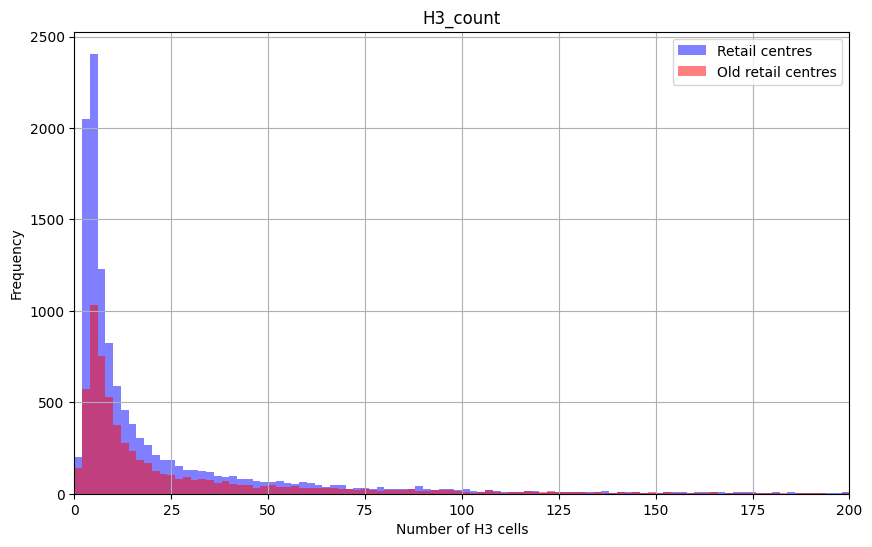

In [45]:
#plot both on same axis
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title("Retail centres")
#hist range is 0-1000
ax.set_xlim(0, 1000)
#plot retail_centres
retail_centres.hist(column="trackNodes", bins=100, log=True, ax=ax, color="blue", alpha=0.5, range=(0, 1000))
#plot old_retail_centres
old_retail_centres.hist(column="H3_count", bins=100, log=True, ax=ax, color="red", alpha=0.5, range=(0, 1000))
plt.xlabel("Number of H3 cells")
plt.ylabel("Frequency")
plt.legend(["Retail centres", "Old retail centres"])
plt.show()


#plot both on same axis
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title("Retail centres")
#hist range is 0-1000
ax.set_xlim(0, 200)
#plot retail_centres
retail_centres.hist(column="trackNodes", bins=100,ax=ax, color="blue", alpha=0.5, range=(0, 200))
#plot old_retail_centres
old_retail_centres.hist(column="H3_count", bins=100,ax=ax, color="red", alpha=0.5, range=(0, 200))
plt.xlabel("Number of H3 cells")
plt.ylabel("Frequency")
plt.legend(["Retail centres", "Old retail centres"])
plt.show()